<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan2/BTVN/MachineLearning2_BTVN_Bai1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


KERNEL: linear
Accuracy: 1.0
Ma tran nham lan:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


KERNEL: rbf
Accuracy: 0.9666666666666667
Ma tran nham lan:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


KERNEL: poly
Accuracy: 0.9
Ma tran nham lan:
[[10  0  0

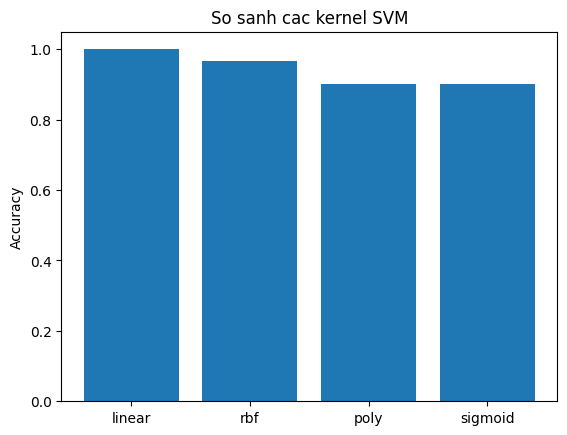


Kernel co Accuracy cao nhat tren test:
Kernel      linear
Accuracy       1.0
Name: 0, dtype: object


In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Nap Iris
iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Thu 4 kernel
results = []

for kernel in ["linear", "rbf", "poly", "sigmoid"]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1, gamma="scale"))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)

    results.append({
        "Kernel": kernel,
        "Accuracy": accuracy
    })

    print("\nKERNEL:", kernel)
    print("Accuracy:", accuracy)
    print("Ma tran nham lan:")
    print(confusion_matrix(y_test, pred))
    print(classification_report(
        y_test, pred,
        target_names=iris.target_names,
        zero_division=0
    ))

df = pd.DataFrame(results)

print("\nBANG SO SANH:")
print(df.to_string(index=False))

plt.bar(df["Kernel"], df["Accuracy"])
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("So sanh cac kernel SVM")
plt.show()

print("\nKernel co Accuracy cao nhat tren test:")
print(df.loc[df["Accuracy"].idxmax()])
